# Predicting land prices in Sri Lanka with ensemble learning

**Question:** what is a perch of land worth, and which kind of ensemble model predicts it best?

In Sri Lanka land prices are mostly decided by a valuer's judgement, and the prices on ikman.lk are all over the place -
10 perches can be advertised at Rs 300,000 or at Rs 15,000,000 per perch. For this project I collected real "Land for Sale"
ads from ikman.lk for Colombo, Gampaha and Kalutara, built features from them and compared bagging, boosting and stacking
models for predicting the price per perch.

In [ ]:
import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

ROOT = Path("..")
sys.path.insert(0, str(ROOT / "src"))      
sys.path.insert(0, str(ROOT / "scraper")) 
from features import clean_listings, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET, KEYWORDS

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGS = ROOT / "report" / "figures"
MODELS = ROOT / "app" / "models"
for folder in [DATA, RESULTS, FIGS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print("scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__,
      "| lightgbm", lgb.__version__, "| catboost", cb.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10


## 1. Data collection (ikman.lk)

The scraper (`scraper/scrape_ikman.py`) goes through the public "Land for Sale" pages for every area in Colombo, Gampaha
and Kalutara (1-3 pages per area) and waits 1.5 s between requests. Each page has the ad data inside a JSON object
(`window.initialData`), so I read the title, size, price, area and ad flags from there.

Notes:
* I checked ikman's `robots.txt` and it does not block these pages (23 Nov 2026). No names or phone numbers are saved.
* These are asking prices, not the final selling prices.

In [2]:
raw_path = DATA / "raw_listings.csv"
if not raw_path.exists():
    import scrape_ikman
    scrape_ikman.main()
raw = pd.read_csv(raw_path)
print(raw.shape)
raw.head()

(5001, 16)


,id,district,area,title,details,price,is_featured,is_member,membership_level,is_top_ad,is_urgent_ad,is_verified,time_stamp,last_bump,slug,page
0,6afe6e35b1c41c6bee011720,Colombo,Nugegoda,Prime Land for Sale in Maharagama Town,24.0 perches,"Rs 3,850,000 per perch",1,1,premium,0,0,1,5 days,just now,prime-land-for-sale-in-maharagama-town-for-sal...,1
1,6b03b22a60f88b75b411e2dd,Colombo,Nugegoda,Land For Sale At Nugegoda Near 119 Bus Route,6.5 perches,"Rs 3,800,000 per perch",0,1,premium,0,0,0,27 minutes,just now,land-for-sale-at-nugegoda-near-119-bus-route-f...,1
2,6b03182591dcdf5e46c2d2b4,Colombo,Nugegoda,"Nugegoda, 76.45 Perches of Land with a Colonia...",76.45 perches,"Rs 4,500,000 per perch",0,1,premium,0,0,1,12 hours,just now,nugegoda-7645-perches-of-land-with-a-colonial-...,1
3,6b0312e91768cffa0d81c284,Colombo,Nugegoda,Nugegoda Udahamulla 02 Bed Room House on 12 Pe...,12.0 perches,"Rs 37,500,000 total price",0,1,premium,0,0,1,12 hours,just now,nugegoda-udahamulla-02-bed-room-house-on-12-pe...,1
4,6b02ab375863c97454ca0b16,Colombo,Nugegoda,Prime Residential Land For Sale In Pita Kotte ...,13.65 perches,"Rs 2,800,000 per perch",0,0,free,0,0,0,bump_up,19 hours,prime-residential-land-for-sale-in-pita-kotte-...,1


Output recieved: 5,001 ads with 16 columns. The size and price are still text (e.g. "24.0 perches", "Rs 5,700,000 per perch"),
and some ads are houses with no land size, so cleaning is needed before any modelling.

## 2. Cleaning and feature engineering

The raw data was quite messy. All the rules are in `src/features.py`, so the
dashboard uses exactly the same code. The steps, in order:

1. **Fix broken text** - some titles were decoded wrongly (Sinhala letters and dashes looked like `Ã ...`), so I re-decode them.
2. **Remove repeated ads** - same ad id, or same title + size + price.
3. **Read the size and price** - e.g. `"16.1 perches"` -> 16.1, `"2 acres"` -> 320 perches; prices can be per perch, total or per acre.
4. **Price per perch** - I convert every price to rupees per perch, so all ads are on the same scale.
5. **Remove ads from other districts** - some agents post Kurunegala or Ratnapura land under Colombo pages. These are far away, so I drop them.
6. **Fix the area using the title** - if the page says "Colombo 3" but the title says "Nittambuwa", the title is right.
7. **Sanity limits** - 1 to 1,600 perches and Rs 20,000 to Rs 60 million per perch (to remove typos).
8. **Remove duplicate plots** - same area + size + price per perch = the same plot posted many times.
9. **Location features** - distance to Colombo Fort, distance to the nearest expressway entrance, latitude/longitude, and a Colombo 1-15 flag.
10. **Keyword flags from the title** (English and Sinhala) - house, commercial, residential, agricultural, bare land, main road, prime, plots, water view, urgent.
11. **Outliers** - remove ads more than 2 standard deviations from their area's average.
12. **Target** - I predict `log(price per perch)` because the prices are very skewed.

In [3]:
coords = pd.read_csv(DATA / "area_coordinates.csv")
df, clean_log = clean_listings(raw, coords)
df.to_csv(DATA / "clean_land.csv", index=False)
pd.DataFrame(clean_log, columns=["step", "rows"]).to_csv(RESULTS / "cleaning_log.csv", index=False)
print("\nFinal dataset:", df.shape)
df[["district", "area", "title", "perches", "price_type", "price_per_perch", "dist_fort_km"]].head(8)

Scraped rows                                                   5001
After removing duplicate ads (same ad id)                      5001
After removing re-posts (same title, size and price)           4693
After dropping ads with no readable size or price              4682
After removing ads that name a place outside the Western Province   4568
Areas corrected from the title: 447 rows                       4568
After sanity limits (1-1600 perches, Rs 20k-60M per perch)     4527
After removing duplicate plots (same area, size and price per perch)   2993
After removing price outliers (+-2 SD within each area)        2852
After removing land-size outliers (+-2 SD within each area)    2719

Final dataset: (2719, 41)


,district,area,title,perches,price_type,price_per_perch,dist_fort_km
0,Colombo,Maharagama,Prime Land for Sale in Maharagama Town,24.00,per_perch,3.850000e+06,13.329389
1,Colombo,Nugegoda,Land For Sale At Nugegoda Near 119 Bus Route,6.50,per_perch,3.800000e+06,9.958706
2,Colombo,Nugegoda,Nugegoda Udahamulla 02 Bed Room House on 12 Pe...,12.00,total,3.125000e+06,9.958706
3,Colombo,Kotte,Prime Residential Land For Sale In Pita Kotte ...,13.65,per_perch,2.800000e+06,8.190199
4,Colombo,Nugegoda,Residential Land For Sale In Pangiriwatta Road...,8.00,per_perch,2.850000e+06,9.958706
5,Colombo,Nugegoda,(AFA702) 10 P Bare Land sale At Pagoda Road Nu...,10.00,per_perch,3.600000e+06,9.958706
6,Colombo,Nugegoda,(AFA706) 13.65 P Bare Land sale At Pagoda Road...,13.65,per_perch,2.950000e+06,9.958706
7,Colombo,Nugegoda,"34.28 Perch Edirisinghe Road, Nugegoda",34.28,total,4.375729e+06,9.958706


In [4]:
# Worked example: one random ad and all the features made from it
ex = df.sample(1, random_state=7).iloc[0]
cols = ["title", "page_area", "area", "area_source", "details", "price", "perches", "price_type",
        "price_per_perch", "log_price_per_perch", "lat", "lon", "dist_fort_km", "dist_expressway_km",
        "is_colombo_city", "log_perches", "is_large_land", "price_was_total"] + list(KEYWORDS)
example = ex[cols]
example.to_frame("value").to_csv(RESULTS / "feature_example.csv")
example.to_frame("value")

,value
title,Colombo 5 Thibirigasyaya Terraze 12 Perches La...
page_area,Colombo 5
area,Colombo 5
area_source,page
details,12.0 perches
price,"Rs 13,000,000 per perch"
perches,12.0
price_type,per_perch
price_per_perch,13000000.0
log_price_per_perch,16.38046


**Worked example.** The table above shows one real ad going through all the steps: "Rs 13,000,000 per perch" becomes
`price_per_perch` = 13,000,000 and `log_price_per_perch` = 16.38; Colombo 5 is about 6.0 km from the Fort and 8.7 km from
the nearest expressway entrance; 12 perches gives `log_perches` = 2.48; and the title has none of the keywords, so all
`kw_` flags are 0.

### 2b. Why I removed duplicate plots

While testing I noticed the scores were suspiciously high. Agents often post the same plot many times, so a copy of a
plot can end up in the training set and another copy in the test set. Then the model is not predicting, it is just
remembering the answer. To check this I run the cleaning again **with** the duplicates and train the same Random Forest.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

def quick_rf_r2(data):
    X_all, y_all = data[NUMERIC_FEATURES + CATEGORICAL_FEATURES], data[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
    pipe = Pipeline([("pre", ColumnTransformer([
                        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False), CATEGORICAL_FEATURES),
                        ("num", "passthrough", NUMERIC_FEATURES)])),
                     ("model", RandomForestRegressor(n_estimators=500, max_features=0.5, random_state=SEED, n_jobs=-1))])
    pipe.fit(X_tr, y_tr)
    return r2_score(y_te, pipe.predict(X_te))

df_dups, _ = clean_listings(raw, coords, verbose=False, drop_duplicate_plots=False)
dup_effect = {"rows_with_duplicates": len(df_dups), "rows_without": len(df),
              "rf_r2_with_duplicates": quick_rf_r2(df_dups), "rf_r2_without": quick_rf_r2(df)}
json.dump(dup_effect, open(RESULTS / "duplicate_effect.json", "w"), indent=2)
print(f"With duplicate plots   : {dup_effect['rows_with_duplicates']:,} rows -> RF test R2 = {dup_effect['rf_r2_with_duplicates']:.3f}  (optimistic - leakage)")
print(f"Without duplicate plots: {dup_effect['rows_without']:,} rows -> RF test R2 = {dup_effect['rf_r2_without']:.3f}  (honest - used from here on)")

With duplicate plots   : 4,076 rows -> RF test R2 = 0.919  (optimistic - leakage)
Without duplicate plots: 2,719 rows -> RF test R2 = 0.832  (honest - used from here on)


**Result:** with the duplicates the Random Forest gets **R^2 = 0.919**, without them **0.832**.

**What this means:** the 0.919 looks better, but it is fake - it comes from the same plots being in both the training and
test sets (data leakage). This is a most important thing that found in the project: a cleaning mistake changed
the score by almost 0.09, much more than changing the algorithm does later (about 0.01). From here onwards only use the
2,719 unique plots.

## 3. Exploratory data analysis

Before modelling I wanted to see how prices are distributed and what seems to drive them.

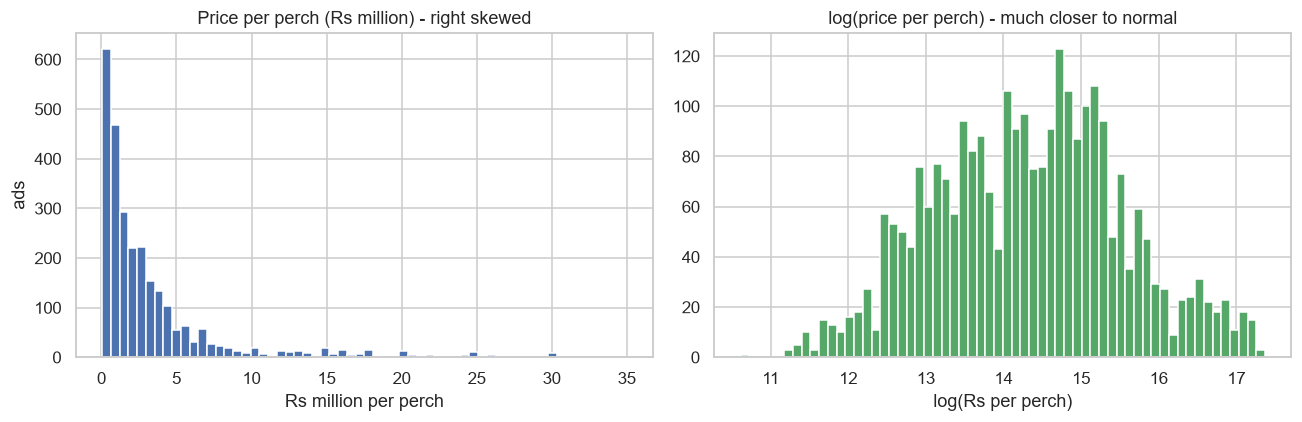

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["price_per_perch"] / 1e6, bins=60, color="#4C72B0")
ax[0].set(title="Price per perch (Rs million) - right skewed", xlabel="Rs million per perch", ylabel="ads")
ax[1].hist(df["log_price_per_perch"], bins=60, color="#55A868")
ax[1].set(title="log(price per perch) - much closer to normal", xlabel="log(Rs per perch)")
plt.tight_layout(); plt.savefig(FIGS / "01_target_distribution.png", bbox_inches="tight"); plt.show()

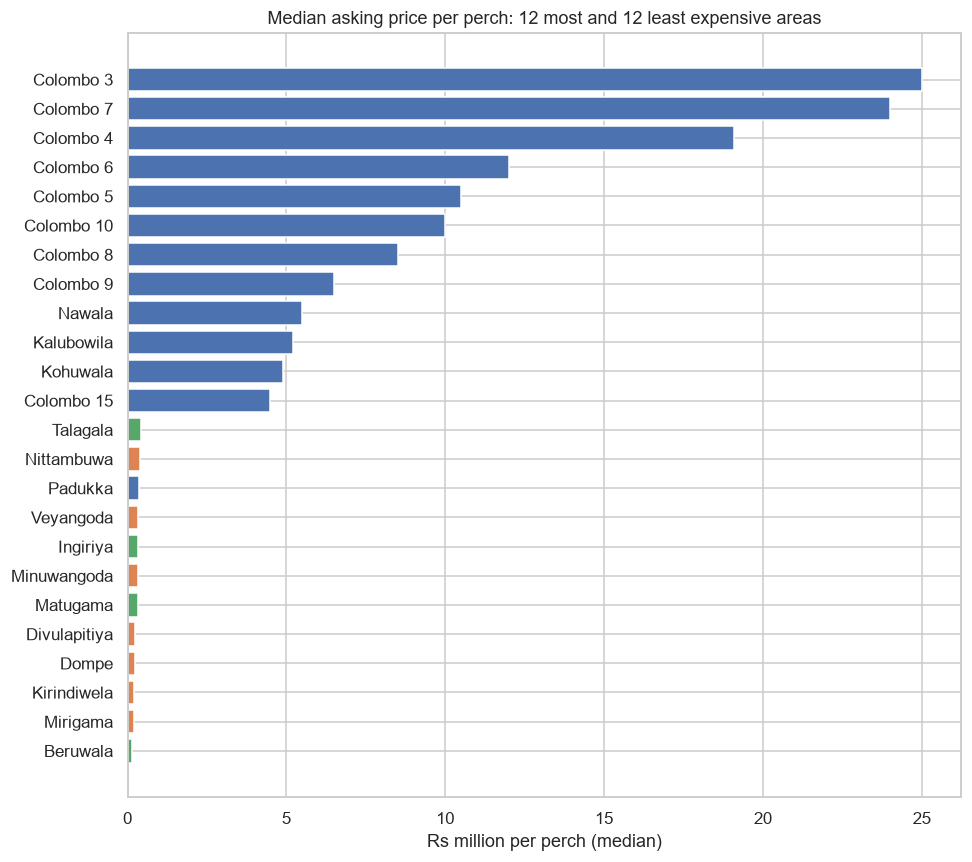

In [7]:
area_stats = (df.groupby(["district", "area"])["price_per_perch"]
                .agg(ads="count", median="median").reset_index().query("ads >= 10")
                .sort_values("median", ascending=False))
area_stats.to_csv(RESULTS / "area_medians.csv", index=False)
top = pd.concat([area_stats.head(12), area_stats.tail(12)])
fig, ax = plt.subplots(figsize=(9, 8))
colors = top["district"].map({"Colombo": "#4C72B0", "Gampaha": "#DD8452", "Kalutara": "#55A868"})
ax.barh(top["area"], top["median"] / 1e6, color=colors)
ax.invert_yaxis()
ax.set(title="Median asking price per perch: 12 most and 12 least expensive areas",
       xlabel="Rs million per perch (median)")
plt.tight_layout(); plt.savefig(FIGS / "02_area_medians.png", bbox_inches="tight"); plt.show()

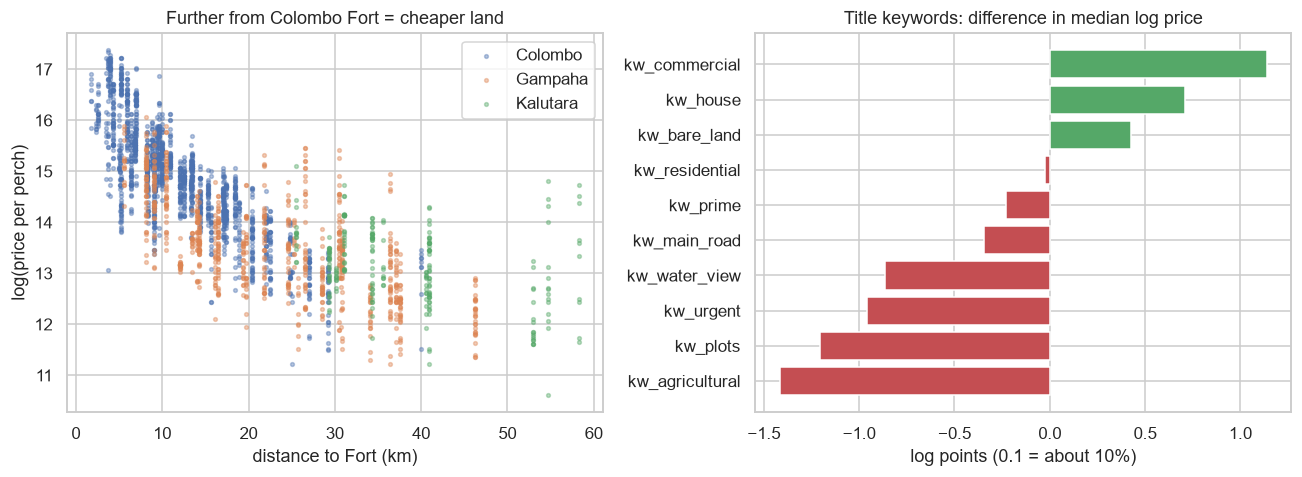

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for d, c in [("Colombo", "#4C72B0"), ("Gampaha", "#DD8452"), ("Kalutara", "#55A868")]:
    s = df[df.district == d]
    ax[0].scatter(s["dist_fort_km"], s["log_price_per_perch"], s=6, alpha=0.4, color=c, label=d)
ax[0].set(title="Further from Colombo Fort = cheaper land", xlabel="distance to Fort (km)",
          ylabel="log(price per perch)")
ax[0].legend()
kw_effect = pd.DataFrame({k: [df.loc[df[k] == 1, TARGET].median() - df.loc[df[k] == 0, TARGET].median()]
                          for k in KEYWORDS}).T[0].sort_values()
ax[1].barh(kw_effect.index, kw_effect.values, color=np.where(kw_effect.values > 0, "#55A868", "#C44E52"))
ax[1].set(title="Title keywords: difference in median log price", xlabel="log points (0.1 = about 10%)")
plt.tight_layout(); plt.savefig(FIGS / "03_distance_keywords.png", bbox_inches="tight"); plt.show()
kw_effect.to_csv(RESULTS / "keyword_effects.csv")

**What I identified in the charts:**
* Prices are very right-skewed (a few Colombo plots are extremely expensive), but `log(price)` looks close to normal.
  That's why I predict the log price - then a 10% error counts the same for a cheap and an expensive plot.
* Location is clearly the main factor: the median price in Colombo 3 and Colombo 7 is around Rs 24-25 million per perch,
  while in Beruwala it is about Rs 140,000 - more than 100 times less. Price falls steadily with distance from the Fort.
* The keyword chart is a raw comparison: "commercial" and "house" ads are more expensive, "agricultural" and "plots" ads
  are cheaper. But this is mostly because of *where* these ads are (agricultural land is far from Colombo), so I expect
  the keywords to matter much less once location is in the model.

## 4. Experimental set-up

To make the comparison fair, every model gets exactly the same data and is measured the same way:

* **Split:** 80% training / 20% test with seed 42. The test set is only used once per model, at the end.
* **Cross-validation:** 5-fold CV on the training set.
* **Encoding:** district and area are one-hot encoded (areas with fewer than 5 ads go into an "infrequent" group).
* **Metrics:**
  * **R^2** - how much of the variation in (log) price the model explains,
  * **RMSE / MAE** on log price
  * **MAPE** - average % error of the price in rupees,
  * training time.

In [9]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape)
cv = KFold(5, shuffle=True, random_state=SEED)

def make_pre(scale=False):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False),
         CATEGORICAL_FEATURES),
        ("num", StandardScaler() if scale else "passthrough", NUMERIC_FEATURES),
    ])

def scores(y_true, y_pred):
    rs_true, rs_pred = np.exp(y_true), np.exp(y_pred)
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred), "MAPE_%": 100 * np.mean(np.abs(rs_true - rs_pred) / rs_true)}

# every model is trained and scored with this same function, so the comparison is fair
LEADER = []   # results of each model
FITTED = {}   # the trained models

def evaluate(name, family, model, scale=False, cv_folds=True):
    pipe = Pipeline([("pre", make_pre(scale)), ("model", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1) if cv_folds else [np.nan]
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    row = {"model": name, "family": family, "CV_R2_mean": np.mean(cv_r2), "CV_R2_std": np.std(cv_r2),
           **scores(y_test, pipe.predict(X_test)), "fit_seconds": fit_s}
    LEADER.append(row); FITTED[name] = pipe
    print(f"{name:<28} CV R2 {row['CV_R2_mean']:.3f} +- {row['CV_R2_std']:.3f} | test R2 {row['R2']:.3f} "
          f"| RMSE {row['RMSE']:.3f} | MAPE {row['MAPE_%']:.1f}% | {fit_s:.1f}s")

train (2175, 23) test (544, 23)


### 4a. Baselines - do we even need ensembles?

Before trying ensembles I need something simple to compare against:

* **Ridge regression** (a linear model). Because every area has its own column, it can already learn each area's
  average price. But it can't learn interactions - for example, it adds the same value for "house" in Colombo 7 and in Mirigama.
* **A single decision tree.** It can learn interactions, but one deep tree tends to memorise the training data (overfitting).

Ensembles should keep the flexibility of trees without the overfitting. The question is how much better they are than Ridge.

In [10]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
evaluate("Ridge regression", "Baseline", Ridge(alpha=1.0), scale=True)
evaluate("Single decision tree", "Baseline", DecisionTreeRegressor(random_state=SEED))

Ridge regression             CV R2 0.835 +- 0.005 | test R2 0.823 | RMSE 0.511 | MAPE 48.0% | 0.1s


Single decision tree         CV R2 0.746 +- 0.016 | test R2 0.713 | RMSE 0.651 | MAPE 64.6% | 0.0s


**Results:** Ridge regression reaches **CV R^2 = 0.835** (test 0.823). The single decision tree only gets **0.746** (test 0.713).

**Why:** Ridge is already strong because it has one column per area, so it knows the average price of each area, and
location explains most of the price. The single tree is much worse because it overfits - its CV score varies more
between folds (+-0.016 vs +-0.005 for Ridge), which is a sign of high variance. So the ensembles have to beat **0.835**
to be worth it.

## 5. Bagging - many trees in parallel (reduces variance)

**Bagging** = Bootstrap AGGregatING. Train many deep trees, each on a random sample of the rows (drawn with replacement),
and **average** their predictions. Each tree makes different mistakes, so the mistakes partly cancel out.

* **Bagging regressor** - plain bagging of decision trees.
* **Random Forest** - bagging, and each split also only looks at a random subset of the features, so the trees are more different from each other.
* **Extra Trees** - like Random Forest, but the split points are chosen randomly too.

In [11]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor
evaluate("Bagging (decision trees)", "Bagging",
         BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, random_state=SEED, n_jobs=-1))
evaluate("Random Forest", "Bagging",
         RandomForestRegressor(n_estimators=500, max_features=0.5, random_state=SEED, n_jobs=-1))
evaluate("Extra Trees", "Bagging",
         ExtraTreesRegressor(n_estimators=500, max_features=0.5, random_state=SEED, n_jobs=-1))

Bagging (decision trees)     CV R2 0.839 +- 0.009 | test R2 0.830 | RMSE 0.501 | MAPE 46.4% | 1.3s


Random Forest                CV R2 0.839 +- 0.009 | test R2 0.832 | RMSE 0.498 | MAPE 45.9% | 1.0s


Extra Trees                  CV R2 0.804 +- 0.015 | test R2 0.800 | RMSE 0.543 | MAPE 50.6% | 1.2s


**Results:** Bagging and Random Forest both reach **CV R^2 = 0.839** (test 0.830 and 0.832). Extra Trees only gets **0.804**.

**Why:**
* Bagging fixed the single tree's problem: from 0.746 to 0.839. Averaging hundreds of trees cancels out the overfitting of each one.
* Random Forest is only slightly better than Ridge (0.839 vs 0.835). Most of the price is explained by the area, which Ridge already captures.
* Extra Trees did worst. My guess is that its random split points throw away useful information, and with only ~2,000 rows that hurts more than it helps.

## 6. Boosting - small trees one after another (reduces bias)

In **boosting**, trees are trained in sequence. Each new (small) tree tries to fix the errors the previous trees still make.

* **AdaBoost** - gives more weight to the rows that were predicted badly.
* **Gradient Boosting** - each new tree is fitted to the residuals (errors) of the current model.
* **XGBoost** - gradient boosting with regularisation and a lot of speed tricks.
* **LightGBM** - grows trees leaf by leaf; very fast, made for big datasets.
* **CatBoost** - uses symmetric trees and "ordered boosting"; good with categorical data.

In [12]:
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
evaluate("AdaBoost", "Boosting",
         AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=300, learning_rate=0.05, random_state=SEED))
evaluate("Gradient Boosting (sklearn)", "Boosting",
         GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEED))
evaluate("XGBoost", "Boosting", xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5,
         subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1))
evaluate("LightGBM", "Boosting", lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31,
         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1))
evaluate("CatBoost", "Boosting", cb.CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6,
         random_seed=SEED, verbose=0, allow_writing_files=False))

AdaBoost                     CV R2 0.813 +- 0.011 | test R2 0.793 | RMSE 0.553 | MAPE 49.8% | 1.8s


Gradient Boosting (sklearn)  CV R2 0.846 +- 0.008 | test R2 0.844 | RMSE 0.481 | MAPE 44.4% | 1.9s


XGBoost                      CV R2 0.842 +- 0.008 | test R2 0.841 | RMSE 0.485 | MAPE 45.6% | 1.0s


LightGBM                     CV R2 0.830 +- 0.010 | test R2 0.841 | RMSE 0.485 | MAPE 46.3% | 0.5s


CatBoost                     CV R2 0.846 +- 0.008 | test R2 0.842 | RMSE 0.483 | MAPE 45.2% | 1.8s


**Results (CV R^2):** Gradient Boosting **0.846**, CatBoost **0.846**, XGBoost **0.842**, LightGBM **0.830**, AdaBoost **0.813**.

**Why:**
* The gradient boosting models are the best family so far, a little above bagging (0.846 vs 0.839). Bagging mainly reduces
  variance, but after cleaning the data the bigger problem was bias - the patterns Ridge and single trees miss. Boosting
  attacks exactly that by fixing the remaining errors step by step.
* LightGBM scores well on the test set (0.841) but lower in CV (0.830). Its leaf-wise trees are designed for big data and
  are less stable with only ~2,000 rows. This is also a good example of why I rank by CV: on the test set alone, LightGBM would look as good as XGBoost.
* AdaBoost is the weakest. It gives more weight to the hardest rows, and in my data the hardest rows are probably often just badly priced ads (noise), so it ends up chasing noise.

### 6c. Stacking - combining different models

In **stacking**, several different models (the base models) make predictions, and then a simple **meta-model** learns how to
combine them. My base models are Random Forest, Extra Trees, XGBoost and CatBoost, and the meta-model is Ridge regression.
The meta-model is trained on out-of-fold predictions (`cv=5`), otherwise it would learn from predictions on data the base
models had already seen. I also try **Voting**, which is just the plain average of the same models.

In [13]:
from sklearn.ensemble import StackingRegressor, VotingRegressor
# base models: two bagging models and two boosting models (boost_a = XGBoost, boost_b = CatBoost)
boost_a = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8,
                           colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
boost_b = cb.CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0,
                               allow_writing_files=False)
base_models = [
    ("rf", RandomForestRegressor(n_estimators=400, max_features=0.5, random_state=SEED, n_jobs=-1)),
    ("et", ExtraTreesRegressor(n_estimators=400, max_features=0.5, random_state=SEED, n_jobs=-1)),
    ("boost_a", boost_a),
    ("boost_b", boost_b),
]
evaluate("Stacking (RF+ET+2 boosters -> Ridge)", "Stacking",
         StackingRegressor(base_models, final_estimator=RidgeCV(), cv=5, n_jobs=1))
evaluate("Voting (simple average)", "Stacking", VotingRegressor(base_models))

stack = FITTED["Stacking (RF+ET+2 boosters -> Ridge)"].named_steps["model"]
meta_weights = pd.Series(stack.final_estimator_.coef_, index=[n for n, _ in base_models])
print("\nMeta-model weights (how much the stack trusts each base model):"); print(meta_weights.round(3))
meta_weights.to_csv(RESULTS / "stacking_weights.csv")

Stacking (RF+ET+2 boosters -> Ridge) CV R2 0.847 +- 0.007 | test R2 0.844 | RMSE 0.480 | MAPE 44.4% | 28.0s


Voting (simple average)      CV R2 0.842 +- 0.010 | test R2 0.839 | RMSE 0.487 | MAPE 45.5% | 6.3s

Meta-model weights (how much the stack trusts each base model):
rf         0.450
et        -0.136
boost_a   -0.060
boost_b    0.733
dtype: float64


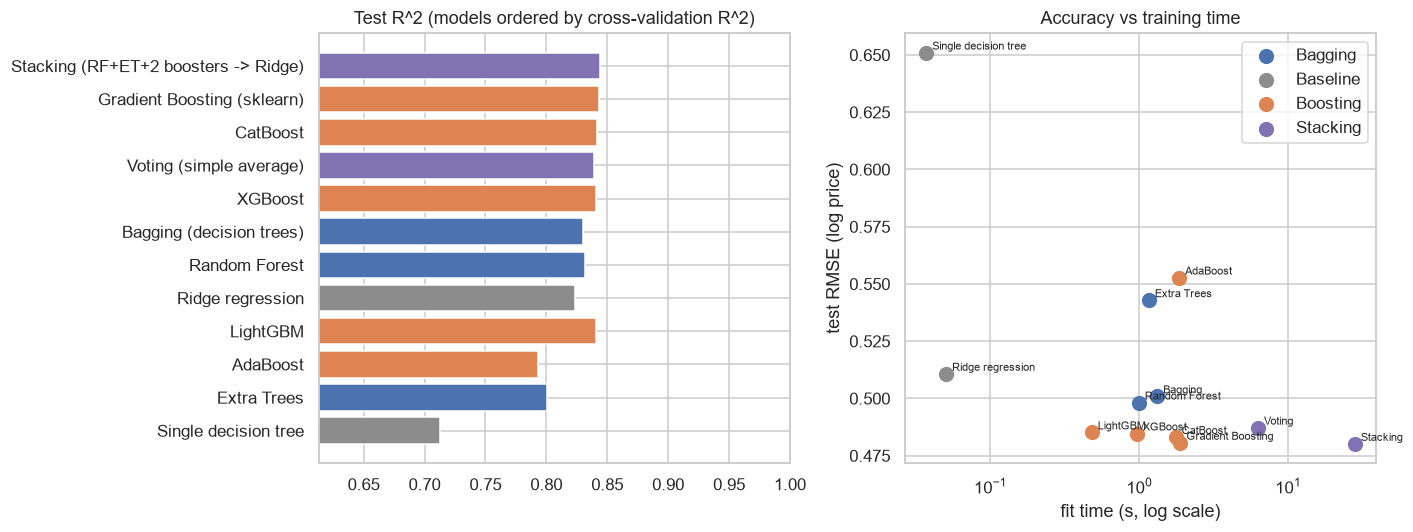

,model,family,CV_R2_mean,CV_R2_std,RMSE,MAE,R2,MAPE_%,fit_seconds
0,Stacking (RF+ET+2 boosters -> Ridge),Stacking,0.847,0.007,0.480,0.332,0.844,44.428,28.021
1,Gradient Boosting (sklearn),Boosting,0.846,0.008,0.481,0.336,0.844,44.447,1.888
2,CatBoost,Boosting,0.846,0.008,0.483,0.337,0.842,45.211,1.753
3,Voting (simple average),Stacking,0.842,0.010,0.487,0.336,0.839,45.465,6.262
4,XGBoost,Boosting,0.842,0.008,0.485,0.335,0.841,45.594,0.962
5,Bagging (decision trees),Bagging,0.839,0.009,0.501,0.342,0.830,46.440,1.317
6,Random Forest,Bagging,0.839,0.009,0.498,0.340,0.832,45.858,0.991
7,Ridge regression,Baseline,0.835,0.005,0.511,0.367,0.823,48.024,0.050
8,LightGBM,Boosting,0.830,0.010,0.485,0.344,0.841,46.327,0.479
9,AdaBoost,Boosting,0.813,0.011,0.553,0.420,0.793,49.846,1.849


In [14]:
leader = pd.DataFrame(LEADER).sort_values("CV_R2_mean", ascending=False).reset_index(drop=True)  # ranked by cross-validation, not by the test set
leader.to_csv(RESULTS / "leaderboard.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pal = {"Baseline": "#8C8C8C", "Bagging": "#4C72B0", "Boosting": "#DD8452", "Stacking": "#8172B3"}
ax[0].barh(leader["model"], leader["R2"], color=leader["family"].map(pal)); ax[0].invert_yaxis()
ax[0].set(title="Test R^2 (models ordered by cross-validation R^2)", xlim=(max(0, leader["R2"].min() - 0.1), 1))
for fam, g in leader.groupby("family"):
    ax[1].scatter(g["fit_seconds"], g["RMSE"], s=80, color=pal[fam], label=fam)
    for _, r in g.iterrows():
        ax[1].annotate(r["model"].split(" (")[0], (r["fit_seconds"], r["RMSE"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[1].set(xscale="log", title="Accuracy vs training time", xlabel="fit time (s, log scale)", ylabel="test RMSE (log price)")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIGS / "04_leaderboard.png", bbox_inches="tight"); plt.show()
leader.round(3)

**Results:** Stacking is ranked first (**CV R^2 = 0.847**, test 0.844, MAPE 44.4%), but it is only 0.001 above Gradient Boosting
and CatBoost, while taking 28 s to train instead of about 2 s. Voting (0.842) is no better than its best member.

**Why stacking only helps a little:** stacking works best when the base models make *different* mistakes. Here all four
are tree ensembles trained on the same features, so their mistakes are very similar. The meta-model weights show this:
it mainly trusts CatBoost (0.73) and Random Forest (0.45), and gives small negative weights to Extra Trees and XGBoost.
A negative weight does not mean those models are bad; because they are so similar to the others, the meta-model
uses them as small corrections.

**Overall comparison:**
* Best ensemble vs Ridge: 0.847 vs 0.835 CV R^2, and MAPE 44.4% vs 48.0%. A real improvement, but a modest one.
* All the good ensembles are within about 0.01 of each other. Which family you choose matters much less than cleaning
  the data and choosing good features.
* MAPE is still about 44%. That sounds high, but these are asking prices typed by sellers, and I only know the town, not the
  exact location of each plot. Two plots in the same town can have very different prices.

## 7. Random Forest vs XGBoost

To be fair to both, I tune both with `RandomizedSearchCV`
(30 random settings x 5-fold CV, using the training set only) and then compare accuracy, stability, speed and
which features they use.

In [15]:
rf_search = RandomizedSearchCV(
    Pipeline([("pre", make_pre()), ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))]),
    {"model__n_estimators": [200, 400, 600, 800], "model__max_depth": [None, 10, 20, 30],
     "model__max_features": [0.3, 0.5, 0.7, 1.0, "sqrt"], "model__min_samples_leaf": [1, 2, 3, 5],
     "model__min_samples_split": [2, 4, 6], "model__bootstrap": [True, False]},
    n_iter=30, cv=cv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
t0 = time.perf_counter(); rf_search.fit(X_train, y_train); rf_tune_s = time.perf_counter() - t0
print("RF best params:", rf_search.best_params_, f"({rf_tune_s:.0f}s)")

bname = "XGBoost"
xgb_grid = {"model__n_estimators": [300, 600, 900, 1200], "model__learning_rate": [0.02, 0.05, 0.1],
            "model__max_depth": [3, 4, 5, 6, 8], "model__subsample": [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.5, 0.7, 0.9, 1.0], "model__min_child_weight": [1, 3, 5, 10],
            "model__reg_lambda": [0.5, 1, 2, 5], "model__reg_alpha": [0, 0.01, 0.1]}
xgb_search = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("model", xgb.XGBRegressor(random_state=SEED, n_jobs=-1))]),
                                xgb_grid,
                                n_iter=30, cv=cv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
t0 = time.perf_counter(); xgb_search.fit(X_train, y_train); xgb_tune_s = time.perf_counter() - t0
print(f"{bname} best params:", xgb_search.best_params_, f"({xgb_tune_s:.0f}s)")

RF best params: {'model__n_estimators': 600, 'model__min_samples_split': 4, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 10, 'model__bootstrap': True} (137s)


XGBoost best params: {'model__subsample': 0.6, 'model__reg_lambda': 1, 'model__reg_alpha': 0.1, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 6, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.5} (82s)


In [16]:
duel = []
fold_scores = {}
for name, search, tune_s in [("Random Forest (tuned)", rf_search, rf_tune_s), (f"{bname} (tuned)", xgb_search, xgb_tune_s)]:
    best = search.best_estimator_
    fold_scores[name] = cross_val_score(best, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    t0 = time.perf_counter(); best.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = best.predict(X_test); pred_ms = 1000 * (time.perf_counter() - t0) / len(X_test)
    duel.append({"model": name, **scores(y_test, pred), "CV_R2_mean": fold_scores[name].mean(),
                 "CV_R2_std": fold_scores[name].std(), "fit_seconds": fit_s, "tuning_seconds": tune_s,
                 "predict_ms_per_row": pred_ms, "best_params": json.dumps(search.best_params_, default=str)})
    FITTED[name] = best
duel = pd.DataFrame(duel); duel.to_csv(RESULTS / "rf_vs_xgb.csv", index=False)
duel.drop(columns="best_params").round(4)

,model,RMSE,MAE,R2,MAPE_%,CV_R2_mean,CV_R2_std,fit_seconds,tuning_seconds,predict_ms_per_row
0,Random Forest (tuned),0.4896,0.3360,0.8377,44.5482,0.8494,0.0066,1.5888,137.0803,0.5158
1,XGBoost (tuned),0.4807,0.3361,0.8435,44.0236,0.8488,0.0068,0.7739,81.9323,0.0373


**Results:** after tuning, Random Forest reaches test **R^2 = 0.838** and XGBoost **0.843**. Both have exactly the same CV R^2
(**0.849**, +-0.007).

**What this means:**
* The difference on the test set (about 0.005) is smaller than the variation between the CV folds (+-0.007), so I would call it a
  **tie** - neither model is really better on this data.
* Tuning helped both a little (Random Forest 0.832 -> 0.838, XGBoost 0.841 -> 0.843).
* XGBoost trains faster (0.8 s vs 1.6 s) and predicts much faster, but needed more settings tuned. Random Forest works
  well with almost default settings. For this problem I would pick Random Forest for simplicity, or XGBoost if speed mattered.

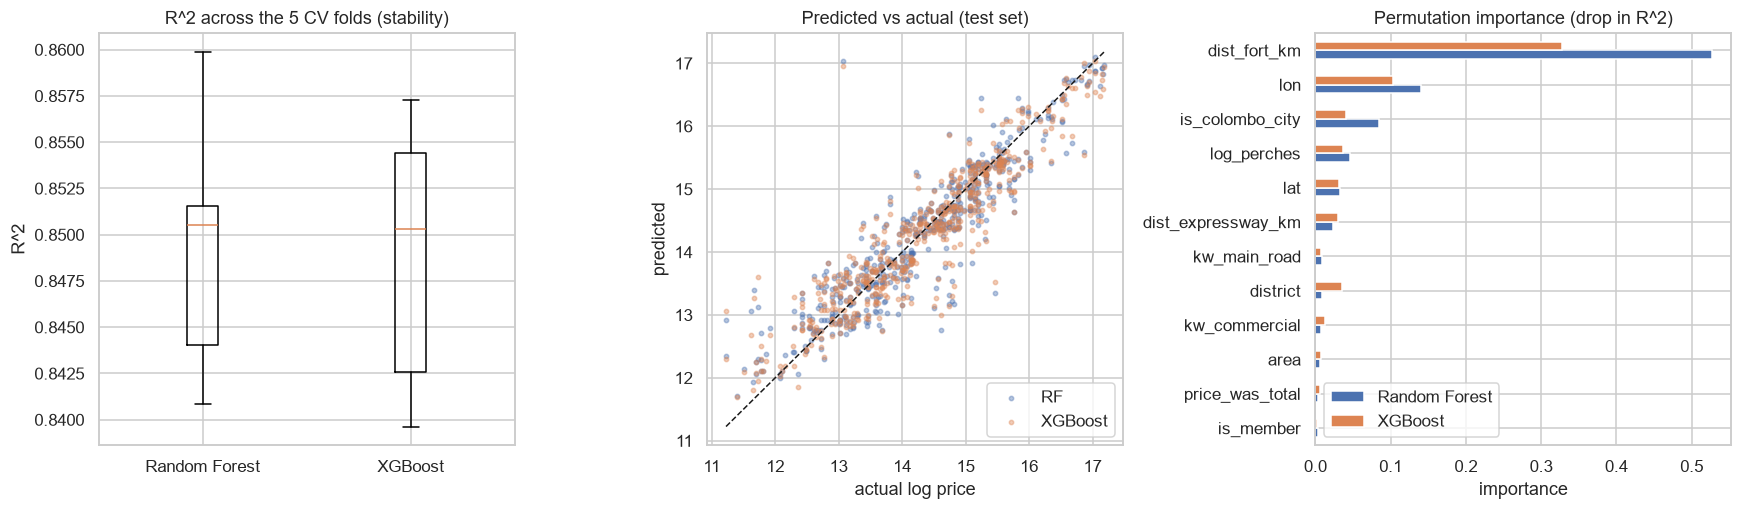

In [17]:
from sklearn.inspection import permutation_importance
rf_best, xg_best = FITTED["Random Forest (tuned)"], FITTED[f"{bname} (tuned)"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].boxplot(list(fold_scores.values())); ax[0].set_xticks([1, 2], ["Random Forest", bname])
ax[0].set(title="R^2 across the 5 CV folds (stability)", ylabel="R^2")
for m, c, lab in [(rf_best, "#4C72B0", "RF"), (xg_best, "#DD8452", bname)]:
    ax[1].scatter(y_test, m.predict(X_test), s=8, alpha=0.4, color=c, label=lab)
lo, hi = y_test.min(), y_test.max(); ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[1].set(title="Predicted vs actual (test set)", xlabel="actual log price", ylabel="predicted"); ax[1].legend()

imp = {}
for m, lab in [(rf_best, "Random Forest"), (xg_best, bname)]:
    r = permutation_importance(m, X_test, y_test, n_repeats=8, random_state=SEED, n_jobs=-1)
    imp[lab] = pd.Series(r.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp).sort_values("Random Forest", ascending=True).tail(12)
imp.plot.barh(ax=ax[2], color=["#4C72B0", "#DD8452"])
ax[2].set(title="Permutation importance (drop in R^2)", xlabel="importance")
plt.tight_layout(); plt.savefig(FIGS / "05_rf_vs_xgb.png", bbox_inches="tight"); plt.show()
imp.sort_values("Random Forest", ascending=False).to_csv(RESULTS / "permutation_importance.csv")

**What the importance charts show:** both models depend mostly on the same features - **distance to Colombo Fort** is by far
the most important, followed by longitude, the Colombo 1-15 flag, land size and latitude. The title keywords are near the
bottom. This confirms what I saw in the EDA: price is mostly about **where** the land is and **how big** it is. XGBoost spreads
its importance a bit more evenly, while Random Forest relies very heavily on the distance to the Fort.

## 8. Hybrid: Random Forest + Artificial Neural Network (ANN)

A neural network can learn smooth patterns, but it needs scaled inputs and usually a lot of data. A Random Forest is
robust and tells us which features matter. I tried three ways of combining them:

| Hybrid | Idea |
|---|---|
| **H1 - RF selects features -> ANN** | RF ranks the features and the ANN only uses the top 10 |
| **H2 - RF prediction as an ANN input** | RF's (out-of-fold) prediction is added as an extra input column for the ANN |
| **H3 - ANN corrects RF** | RF predicts first, then a small ANN learns RF's errors; final prediction = RF + ANN |

### The ANN architecture (`MLPRegressor`)

```
input (one-hot district/area + 21 scaled numeric features)
   -> Dense 64, ReLU
   -> Dense 32, ReLU
   -> Dense 1, linear  = predicted log price per perch
```

| Choice | Value | Why I chose it |
|---|---|---|
| Type | Fully-connected MLP | The data is a table, not images or text, so no CNN/RNN is needed |
| Hidden layers | 2 layers (64 -> 32) | Two layers can learn interactions (e.g. distance x size); small, because I only have ~2,000 rows |
| Activation | ReLU | Adds non-linearity, simple and fast |
| Output | Linear | Log price can be any real number |
| Scaling | StandardScaler | Distances go up to 60 but flags are 0/1; the network trains badly without scaling |
| Regularisation | L2, `alpha=0.001` | Keeps the weights small to reduce overfitting |
| Optimiser | Adam, learning rate 0.001 | The usual default, works well without much tuning |
| Early stopping | 15% validation, stop after 30 epochs without improvement | Stops training before it starts memorising |
| H3 network | 32 -> 16, `alpha=0.01` | Smaller and more regularised, because RF's errors are mostly noise |

The next cell prints the exact layer sizes and number of parameters.

In [18]:
from sklearn.neural_network import MLPRegressor
from sklearn.base import clone

def ann():
    return MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3, learning_rate_init=1e-3,
                        max_iter=2000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
                        random_state=SEED)

pre_s = make_pre(scale=True).fit(X_train)
Xtr_s, Xte_s = pre_s.transform(X_train), pre_s.transform(X_test)
feat_names = pre_s.get_feature_names_out()
hyb = []

def log_hybrid(name, pred, fit_s):
    hyb.append({"model": name, **scores(y_test, pred), "fit_seconds": fit_s})
    print(f"{name:<38} R2 {hyb[-1]['R2']:.3f} | RMSE {hyb[-1]['RMSE']:.3f} | MAPE {hyb[-1]['MAPE_%']:.1f}%")

rf_h = clone(rf_search.best_estimator_.named_steps["model"])

# Reference models
t0 = time.perf_counter(); rf_h.fit(Xtr_s, y_train); log_hybrid("RF alone", rf_h.predict(Xte_s), time.perf_counter() - t0)
t0 = time.perf_counter(); a0 = ann().fit(Xtr_s, y_train); log_hybrid("ANN alone", a0.predict(Xte_s), time.perf_counter() - t0)

# H1: RF importance -> keep top-k columns -> ANN
t0 = time.perf_counter()
order = np.argsort(rf_h.feature_importances_)[::-1]
best_k, best_cv = None, -np.inf
for k in [10, 15, 20, 30, 40]:
    k = min(k, len(order)); cols = order[:k]
    s = cross_val_score(ann(), Xtr_s[:, cols], y_train, cv=cv, scoring="r2").mean()
    if s > best_cv: best_k, best_cv = k, s
keep = order[:best_k]
a1 = ann().fit(Xtr_s[:, keep], y_train)
log_hybrid(f"H1 RF-selected top {best_k} -> ANN", a1.predict(Xte_s[:, keep]), time.perf_counter() - t0)
selected_features = list(feat_names[keep])

# H2: out-of-fold RF prediction as an extra input
t0 = time.perf_counter()
rf_oof = cross_val_predict(clone(rf_h), Xtr_s, y_train, cv=cv, n_jobs=-1)
a2 = ann().fit(np.column_stack([Xtr_s, rf_oof]), y_train)
log_hybrid("H2 RF prediction as ANN input", a2.predict(np.column_stack([Xte_s, rf_h.predict(Xte_s)])), time.perf_counter() - t0)

# H3: ANN learns RF's out-of-fold residuals
t0 = time.perf_counter()
resid = y_train.values - rf_oof
a3 = MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-2, max_iter=2000, early_stopping=True,
                  n_iter_no_change=30, random_state=SEED).fit(Xtr_s, resid)
log_hybrid("H3 RF + ANN residual correction", rf_h.predict(Xte_s) + a3.predict(Xte_s), time.perf_counter() - t0)

hyb = pd.DataFrame(hyb); hyb.to_csv(RESULTS / "hybrid_rf_ann.csv", index=False)

def describe(net, name):
    sizes = [net.coefs_[0].shape[0]] + [w.shape[1] for w in net.coefs_]
    n_par = sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)
    return {"network": name, "layers": " -> ".join(map(str, sizes)), "parameters": n_par,
            "epochs_trained": net.n_iter_, "alpha": net.alpha}
ann_arch = pd.DataFrame([describe(a0, "ANN alone"), describe(a1, f"H1 (top {best_k} features)"),
                         describe(a2, "H2 (+ RF prediction)"), describe(a3, "H3 residual corrector")])
ann_arch.to_csv(RESULTS / "ann_architecture.csv", index=False)
print(); print(ann_arch.to_string(index=False))
pd.Series(selected_features).to_csv(RESULTS / "h1_selected_features.csv", index=False)

RF alone                               R2 0.838 | RMSE 0.490 | MAPE 44.5%


ANN alone                              R2 0.773 | RMSE 0.579 | MAPE 50.9%


H1 RF-selected top 10 -> ANN           R2 0.787 | RMSE 0.561 | MAPE 52.1%


H2 RF prediction as ANN input          R2 0.828 | RMSE 0.504 | MAPE 50.1%


H3 RF + ANN residual correction        R2 0.834 | RMSE 0.496 | MAPE 45.4%

              network               layers  parameters  epochs_trained  alpha
            ANN alone 107 -> 64 -> 32 -> 1        9025             180  0.001
 H1 (top 10 features)  10 -> 64 -> 32 -> 1        2817             374  0.001
 H2 (+ RF prediction) 108 -> 64 -> 32 -> 1        9089              77  0.001
H3 residual corrector 107 -> 32 -> 16 -> 1        4001              38  0.010


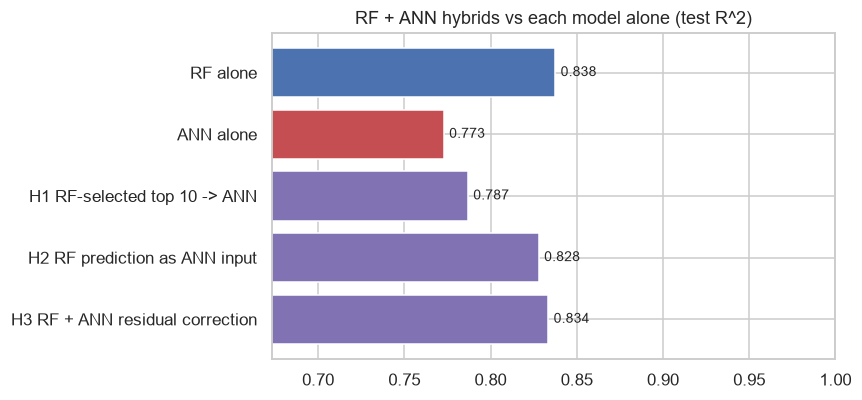

,model,RMSE,MAE,R2,MAPE_%,fit_seconds
0,RF alone,0.4896,0.3360,0.8377,44.5483,1.5995
1,ANN alone,0.5789,0.4068,0.7730,50.9430,3.1520
2,H1 RF-selected top 10 -> ANN,0.5608,0.4005,0.7870,52.1172,55.8603
3,H2 RF prediction as ANN input,0.5037,0.3469,0.8281,50.1283,7.8397
4,H3 RF + ANN residual correction,0.4956,0.3399,0.8336,45.4246,0.4519


In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
cols = ["#4C72B0", "#C44E52", "#8172B3", "#8172B3", "#8172B3"]
ax.barh(hyb["model"], hyb["R2"], color=cols[:len(hyb)]); ax.invert_yaxis()
for i, v in enumerate(hyb["R2"]): ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(title="RF + ANN hybrids vs each model alone (test R^2)", xlim=(max(0, hyb["R2"].min() - 0.1), 1))
plt.tight_layout(); plt.savefig(FIGS / "06_hybrids.png", bbox_inches="tight"); plt.show()
hyb.round(4)

**Results:** RF alone **0.838**, ANN alone **0.773**, H1 **0.787**, H2 **0.828**, H3 **0.834**.

**Why:**
* **The ANN alone is the weakest model.** Neural networks usually need much more data than ~2,000 rows, and most of my
  inputs are 0/1 columns (areas, keywords), which trees handle more naturally.
* **H1 is worse than the ANN alone.** With only the top 10 features the network loses the area columns, which carry a lot of information.
* **H2 and H3 are much better than the ANN alone**, because they use Random Forest's prediction. H3 is the best hybrid,
  but it is still not better than RF alone (0.834 vs 0.838). The forest had already learned the pattern, so there was
  almost nothing left for the ANN to fix - the remaining errors are mostly noise.

So on this kind of small tabular dataset, the hybrid did not add anything over a plain Random Forest.

## 9. Saving the models and results for the dashboard

In [20]:
import joblib
final_models = {
    "Random Forest (tuned)": rf_best,
    f"{bname} (tuned)": xg_best,
    "Stacking": FITTED["Stacking (RF+ET+2 boosters -> Ridge)"],
}
joblib.dump(final_models, MODELS / "final_models.joblib", compress=3)
joblib.dump({"pre_scaled": pre_s, "rf": rf_h, "ann_resid": a3, "ann_h2": a2}, MODELS / "hybrid.joblib", compress=3)

summary = {
    "rows_scraped": int(len(raw)), "rows_clean": int(len(df)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "n_areas": int(df["area"].nunique()), "booster_name": bname,
    "best_overall": leader.iloc[0]["model"], "best_overall_R2": float(leader.iloc[0]["R2"]),
    "best_overall_CV_R2": float(leader.iloc[0]["CV_R2_mean"]), "ranking": "by 5-fold CV R2 on the training set",
    "median_price_per_perch": float(df["price_per_perch"].median()),
    "area_corrected_from_title": int((df["area_source"] == "title").sum()),
    "libs": {"sklearn": sklearn.__version__, "xgboost": xgb.__version__,
             "lightgbm": lgb.__version__, "catboost": cb.__version__},
}
json.dump(summary, open(RESULTS / "summary.json", "w"), indent=2)
summary

{'rows_scraped': 5001,
 'rows_clean': 2719,
 'n_train': 2175,
 'n_test': 544,
 'n_areas': 84,
 'booster_name': 'XGBoost',
 'best_overall': 'Stacking (RF+ET+2 boosters -> Ridge)',
 'best_overall_R2': 0.8438524551764836,
 'best_overall_CV_R2': 0.8471937495204444,
 'ranking': 'by 5-fold CV R2 on the training set',
 'median_price_per_perch': 1700000.0,
 'area_corrected_from_title': 267,
 'libs': {'sklearn': '1.9.1',
  'xgboost': '3.4.1',
  'lightgbm': '4.7.0',
  'catboost': '1.2.10'}}

## 10. Research: comparing the ensemble methods

### RF vs Gradient Boosting (XGBoost, LightGBM, CatBoost)

| | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Family | Bagging | Boosting | Boosting | Boosting |
| How trees are built | In parallel, deep, independent | One after another, shallow | One after another, leaf by leaf | One after another, symmetric trees |
| Mainly reduces | Variance | Bias | Bias | Bias |
| Tuning needed | Low - defaults are good | High (learning rate, depth, number of trees ...) | High; can overfit small data | Medium |
| Speed | Fast (parallel) | Fast | Usually the fastest on big data | Slower to train |
| Categorical data | Needs encoding | Needs encoding | Built-in support | Best built-in support |
| Overfitting risk | Low | Medium | Higher on small data | Low |
| In my results (CV R^2) | 0.839 | 0.842 | 0.830 | 0.846 |

LightGBM was the weakest booster here, which fits the table: it is made for big datasets and its leaf-wise trees can
overfit when there are only ~2,000 rows.

## 11. Conclusions

**1. Data quality mattered most.** I collected 5,001 ads and ended with 2,719 unique plots in 84 areas. Removing duplicate
plots changed the Random Forest score from 0.919 to 0.832 - the higher score was leakage. Removing ads from other
districts and fixing the area from the title was also necessary before any model could be trusted.

**2. Best model.** Ranked by cross-validation, the best model was the stacking ensemble (Random Forest + Extra Trees +
XGBoost + CatBoost -> Ridge): CV R^2 0.847, test R^2 0.844, MAPE 44.4%.

**3. Bagging vs boosting vs stacking.** Boosting (0.846) was slightly better than bagging (0.839) because after cleaning
the main problem was bias, not variance. Stacking added only 0.001, because its base models make similar mistakes.

**4. Ensembles vs a simple model.** The best ensemble beat Ridge regression by 0.012 CV R^2 and 3.6 MAPE points - a real
but modest gain.

**5. Random Forest vs XGBoost.** After tuning they tie (CV R^2 0.849 for both; test 0.838 vs 0.843).

**6. RF + ANN.** The ANN alone was the weakest model (0.773) because the dataset is small. The best hybrid (0.834) did
not beat Random Forest alone (0.838).

**7. What drives land prices.** Distance to Colombo Fort, location and plot size. These matter much more than which
algorithm is used.

**Limitations:** these are asking prices, not sale prices; I only know the town, not the exact location (so distances to schools or
hospitals would be the same for every plot in a town); the coordinates are approximate; the data is one snapshot, so
RF + ARIMA could not be applied; and outliers were removed before the train/test split.

**Future work:** open each ad page to get the exact location, add distance to schools, hospitals and railway stations,
and scrape every month to build a price index that RF + ARIMA could forecast.